In [4]:
# ============================================================
# SENTINEL-1 OAT FIELD ANALYSIS - SETUP
# ============================================================

from pathlib import Path
import re

import numpy as np
import pandas as pd
import rasterio
import seaborn as sns
import matplotlib.pyplot as plt

# Configuration
DATA_ROOT = Path("data/fields/data")
OUTPUT_DIR = Path("data/boxplots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_FORMATS = ["png", "jpg"]

print(f"Output directory: {OUTPUT_DIR}")

Output directory: data\boxplots


In [5]:
# ============================================================
# HELPER FUNCTIONS
# ============================================================

def extract_date_tokens(filename):
    """Extract date tokens from raster filename."""
    tokens = re.findall(r"\d{8}T\d{6}|\d{8}", filename)
    if not tokens:
        raise ValueError(f"Could not parse a date from: {filename}")
    return tokens


def token_to_date_string(token):
    """Convert date token to YYYY-MM-DD."""
    fmt = "%Y%m%dT%H%M%S" if "T" in token else "%Y%m%d"
    return pd.to_datetime(token, format=fmt).strftime("%Y-%m-%d")


def parse_date_fields(filename, raster_type):
    """Create display label and sort key for date axis."""
    tokens = extract_date_tokens(filename)
    start_date = token_to_date_string(tokens[0])
    start_sort = pd.to_datetime(start_date)

    if raster_type == "coherence" and len(tokens) >= 2:
        end_date = token_to_date_string(tokens[1])
        date_label = f"{start_date} - {end_date}"
    else:
        date_label = start_date

    return date_label, start_sort


def infer_backscatter_labels(src):
    """Infer VV/VH labels from raster band descriptions, with a safe fallback."""
    descriptions = [(desc or "").upper() for desc in src.descriptions]
    if any("VV" in desc or "VH" in desc for desc in descriptions):
        labels = []
        for index, desc in enumerate(descriptions, start=1):
            if "VV" in desc:
                labels.append("VV")
            elif "VH" in desc:
                labels.append("VH")
            else:
                labels.append(f"Band {index}")
        return labels
    if src.count >= 2:
        return ["VV", "VH"] + [f"Band {i}" for i in range(3, src.count + 1)]
    if src.count == 1:
        return ["VV"]
    return [f"Band {i}" for i in range(1, src.count + 1)]


def iter_field_rasters(root):
    """Yield every extracted raster stored under the per-field dataset folders."""
    for field_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        for variable, subfolder in [("backscatter", "backscatter"), ("coherence", "coherence")]:
            folder = field_dir / subfolder
            if not folder.exists():
                continue
            for raster_path in sorted(folder.glob("*.tif")):
                yield field_dir.name, variable, raster_path


def build_pixel_table(root):
    """Build one long table with every valid pixel value across all fields and dates."""
    tables = []

    for field_id, raster_type, raster_path in iter_field_rasters(root):
        date_label, date_sort = parse_date_fields(raster_path.name, raster_type)
        with rasterio.open(raster_path) as src:
            data = src.read(masked=True)

            if raster_type == "backscatter":
                band_labels = infer_backscatter_labels(src)
            else:
                band_labels = ["Coherence"] * src.count

            for band_index in range(src.count):
                values = data[band_index].compressed()
                values = values[np.isfinite(values)]

                if raster_type == "coherence":
                    values = values[(values >= 0) & (values <= 1)]

                if values.size == 0:
                    continue

                variable = band_labels[band_index] if band_index < len(band_labels) else f"Band {band_index + 1}"
                frame = pd.DataFrame({
                    "Date": date_label,
                    "DateSort": date_sort,
                    "Variable": variable,
                    "Value": values.astype(float),
                    "FieldId": field_id,
                    "Source": raster_path.name,
                })
                tables.append(frame)

    if not tables:
        return pd.DataFrame(columns=["Date", "DateSort", "Variable", "Value", "FieldId", "Source"])
    return pd.concat(tables, ignore_index=True)


print("Helper functions defined.")

Helper functions defined.


In [6]:
# ============================================================
# LOAD DATA AND CREATE SUMMARIES
# ============================================================

# Load and prepare data
print(f"Scanning field rasters under: {DATA_ROOT}")
df = build_pixel_table(DATA_ROOT)

if df.empty:
    raise RuntimeError(f"No raster pixels were found under {DATA_ROOT}")

df = df.sort_values(["Variable", "DateSort"]).reset_index(drop=True)

# Display data info
print("\nData sample:")
print(df.head())
print("\nVariable counts:")
print(df["Variable"].value_counts())
print("\nSample by date:")
print(df.groupby(["Variable", "Date"]).size().head())

# Create summary statistics
summary = (
    df.groupby(["Variable", "Date"], as_index=False)
      .agg(
          pixel_count=("Value", "size"),
          mean_value=("Value", "mean"),
          median_value=("Value", "median"),
      )
)

# Save to CSV
df.to_csv(OUTPUT_DIR / "all_pixels_timeseries.csv", index=False)
summary.to_csv(OUTPUT_DIR / "pixel_summary_by_date.csv", index=False)

print(f"\nSaved pixel table to {OUTPUT_DIR / 'all_pixels_timeseries.csv'}")
print(f"Saved summary table to {OUTPUT_DIR / 'pixel_summary_by_date.csv'}")

Scanning field rasters under: data\fields\data

Data sample:
                      Date   DateSort   Variable     Value FieldId  \
0  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.206001   22583   
1  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.215767   22583   
2  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.240988   22583   
3  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.244927   22583   
4  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.189314   22583   

                                              Source  
0  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
1  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
2  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
3  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
4  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  

Variable counts:
Variable
VH           3603890
VV           3603890
Coherence    3276652
Name: count, dtype: int64

Sample by date:
Variable   Date                   
Coherence  2024-06-0

Saved VV boxplot to data\boxplots\vv_boxplot.png
Saved VV boxplot to data\boxplots\vv_boxplot.jpg


Saved VV boxplot to data\boxplots\vv_boxplot.png
Saved VV boxplot to data\boxplots\vv_boxplot.jpg


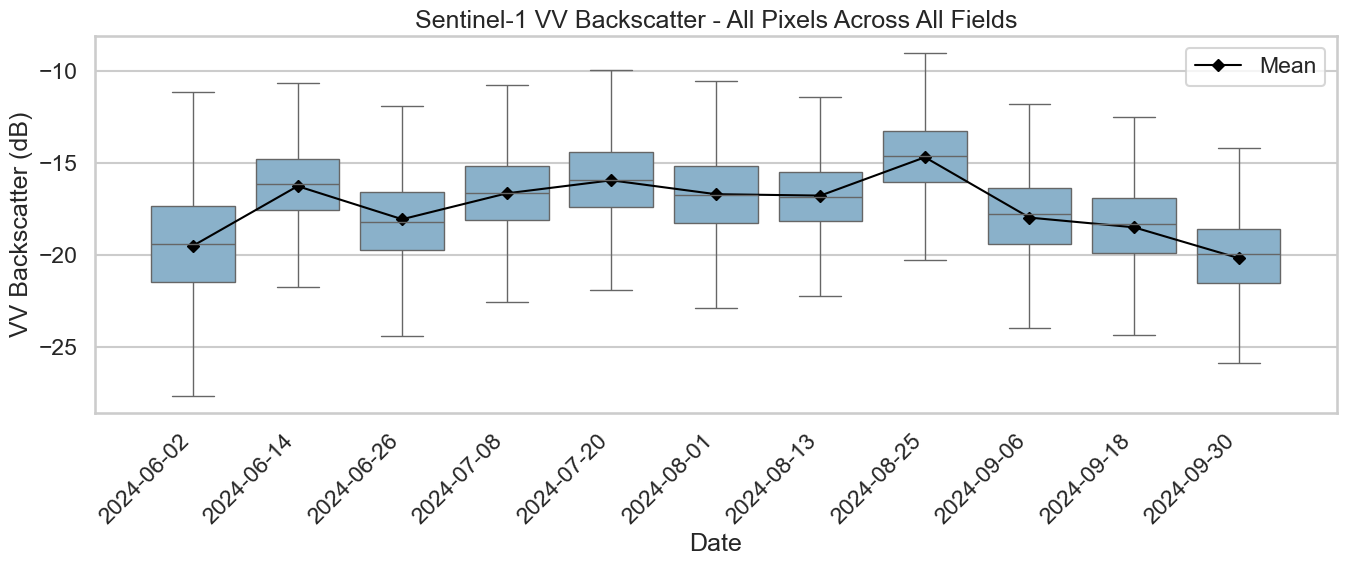

In [7]:
# ============================================================
# BOXPLOT: VV BACKSCATTER
# ============================================================

sns.set_theme(style="whitegrid", context="talk")

# Filter data
subset = df[df["Variable"] == "VV"].copy()

# Calculate means and ensure chronological order
mean_by_date = (
    subset.groupby("Date", as_index=False)
          .agg(
              Value=("Value", "mean"),
              DateSort=("DateSort", "min"),
          )
          .sort_values("DateSort")
)
order = mean_by_date["Date"].tolist()
mean_values = mean_by_date["Value"].tolist()

# Create plot
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=subset, x="Date", y="Value", order=order, showfliers=False, color="#7fb3d5", ax=ax)
ax.plot(range(len(order)), mean_values, marker="D", markersize=6, linewidth=1.5, color="black", label="Mean")

ax.set_title("Sentinel-1 VV Backscatter - All Pixels Across All Fields")
ax.set_xlabel("Date")
ax.set_ylabel("VV Backscatter (dB)")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.legend(loc="best")
fig.tight_layout()

# Save
for image_format in IMAGE_FORMATS:
    output_path = OUTPUT_DIR / f"vv_boxplot.{image_format}"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved VV boxplot to {output_path}")

plt.show()

Saved VH boxplot to data\boxplots\vh_boxplot.png
Saved VH boxplot to data\boxplots\vh_boxplot.jpg


Saved VH boxplot to data\boxplots\vh_boxplot.png
Saved VH boxplot to data\boxplots\vh_boxplot.jpg


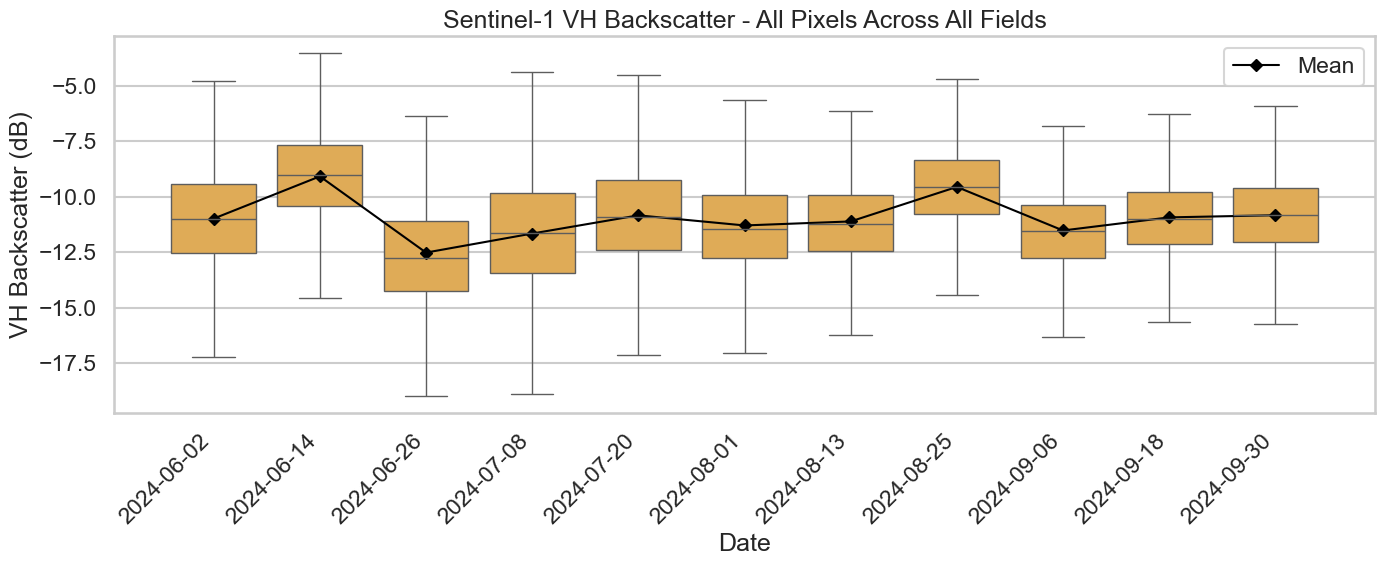

In [8]:
# ============================================================
# BOXPLOT: VH BACKSCATTER
# ============================================================

# Filter data
subset = df[df["Variable"] == "VH"].copy()

# Calculate means and ensure chronological order
mean_by_date = (
    subset.groupby("Date", as_index=False)
          .agg(
              Value=("Value", "mean"),
              DateSort=("DateSort", "min"),
          )
          .sort_values("DateSort")
)
order = mean_by_date["Date"].tolist()
mean_values = mean_by_date["Value"].tolist()

# Create plot
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=subset, x="Date", y="Value", order=order, showfliers=False, color="#f5b041", ax=ax)
ax.plot(range(len(order)), mean_values, marker="D", markersize=6, linewidth=1.5, color="black", label="Mean")

ax.set_title("Sentinel-1 VH Backscatter - All Pixels Across All Fields")
ax.set_xlabel("Date")
ax.set_ylabel("VH Backscatter (dB)")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.legend(loc="best")
fig.tight_layout()

# Save
for image_format in IMAGE_FORMATS:
    output_path = OUTPUT_DIR / f"vh_boxplot.{image_format}"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved VH boxplot to {output_path}")

plt.show()

Saved Coherence boxplot to data\boxplots\coherence_boxplot.png
Saved Coherence boxplot to data\boxplots\coherence_boxplot.jpg


Saved Coherence boxplot to data\boxplots\coherence_boxplot.png
Saved Coherence boxplot to data\boxplots\coherence_boxplot.jpg


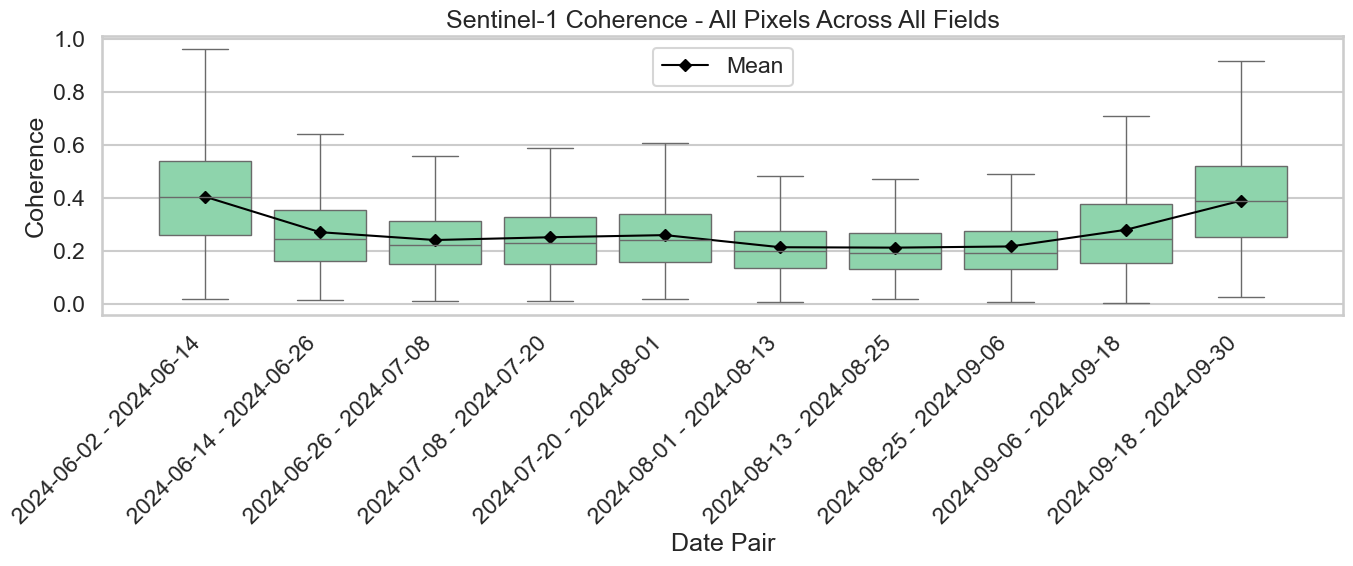


✓ Done. All outputs saved to data\boxplots


In [9]:
# ============================================================
# BOXPLOT: COHERENCE
# ============================================================

# Filter data
subset = df[df["Variable"] == "Coherence"].copy()

# Calculate means and ensure chronological order based on first image date
mean_by_date = (
    subset.groupby("Date", as_index=False)
          .agg(
              Value=("Value", "mean"),
              DateSort=("DateSort", "min"),
          )
          .sort_values("DateSort")
)
order = mean_by_date["Date"].tolist()
mean_values = mean_by_date["Value"].tolist()

# Create plot
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=subset, x="Date", y="Value", order=order, showfliers=False, color="#82e0aa", ax=ax)
ax.plot(range(len(order)), mean_values, marker="D", markersize=6, linewidth=1.5, color="black", label="Mean")

ax.set_title("Sentinel-1 Coherence - All Pixels Across All Fields")
ax.set_xlabel("Date Pair")
ax.set_ylabel("Coherence")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.legend(loc="best")
fig.tight_layout()

# Save
for image_format in IMAGE_FORMATS:
    output_path = OUTPUT_DIR / f"coherence_boxplot.{image_format}"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved Coherence boxplot to {output_path}")

plt.show()

print("\n✓ Done. All outputs saved to", OUTPUT_DIR)

In [10]:
# ============================================================
# SENTINEL-1 OAT FIELD ANALYSIS - SETUP
# ============================================================

from pathlib import Path
import re

import numpy as np
import pandas as pd
import rasterio
import seaborn as sns
import matplotlib.pyplot as plt

# Configuration
DATA_ROOT = Path("data/fields/data")
OUTPUT_DIR = Path("data/boxplots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_FORMATS = ["png", "jpg"]

print(f"Output directory: {OUTPUT_DIR}")

Output directory: data\boxplots


Saved Coherence boxplot to data\boxplots\coherence_boxplot.png
Saved Coherence boxplot to data\boxplots\coherence_boxplot.jpg


Saved Coherence boxplot to data\boxplots\coherence_boxplot.png
Saved Coherence boxplot to data\boxplots\coherence_boxplot.jpg


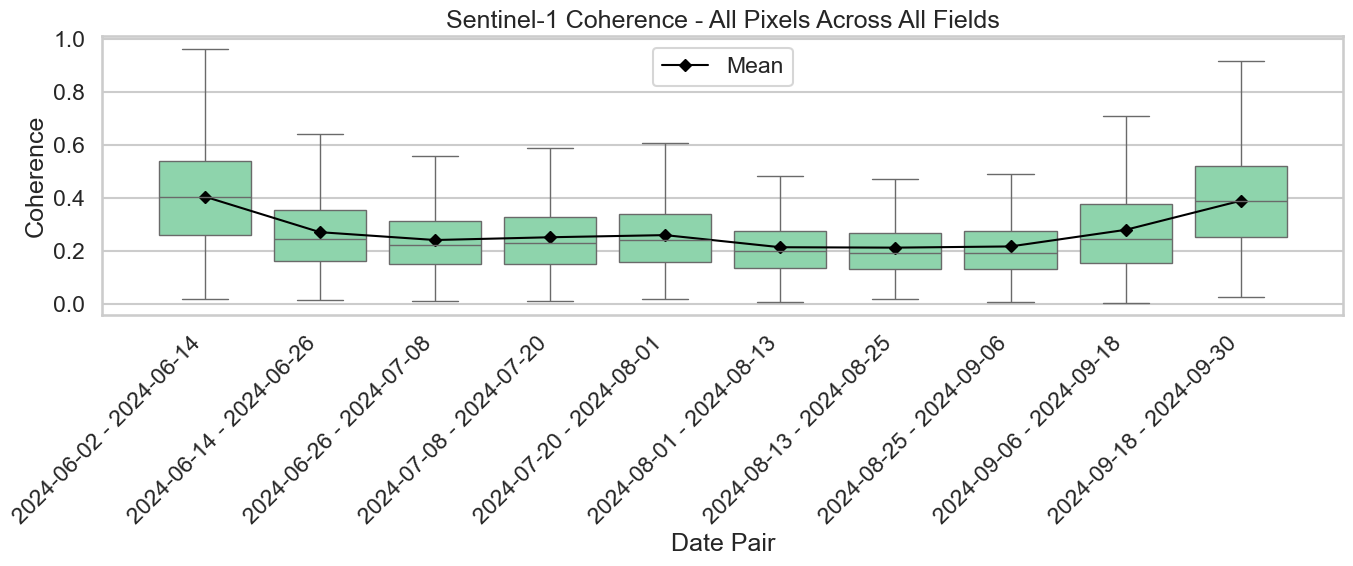


✓ Done. All outputs saved to data\boxplots


In [11]:
# ============================================================
# BOXPLOT: COHERENCE
# ============================================================

# Filter data
subset = df[df["Variable"] == "Coherence"].copy()

# Calculate means and ensure chronological order based on first image date
mean_by_date = (
    subset.groupby("Date", as_index=False)
          .agg(
              Value=("Value", "mean"),
              DateSort=("DateSort", "min"),
          )
          .sort_values("DateSort")
)
order = mean_by_date["Date"].tolist()
mean_values = mean_by_date["Value"].tolist()

# Create plot
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=subset, x="Date", y="Value", order=order, showfliers=False, color="#82e0aa", ax=ax)
ax.plot(range(len(order)), mean_values, marker="D", markersize=6, linewidth=1.5, color="black", label="Mean")

ax.set_title("Sentinel-1 Coherence - All Pixels Across All Fields")
ax.set_xlabel("Date Pair")
ax.set_ylabel("Coherence")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.legend(loc="best")
fig.tight_layout()

# Save
for image_format in IMAGE_FORMATS:
    output_path = OUTPUT_DIR / f"coherence_boxplot.{image_format}"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved Coherence boxplot to {output_path}")

plt.show()

print("\n✓ Done. All outputs saved to", OUTPUT_DIR)

Saved VH boxplot to data\boxplots\vh_boxplot.png
Saved VH boxplot to data\boxplots\vh_boxplot.jpg


Saved VH boxplot to data\boxplots\vh_boxplot.png
Saved VH boxplot to data\boxplots\vh_boxplot.jpg


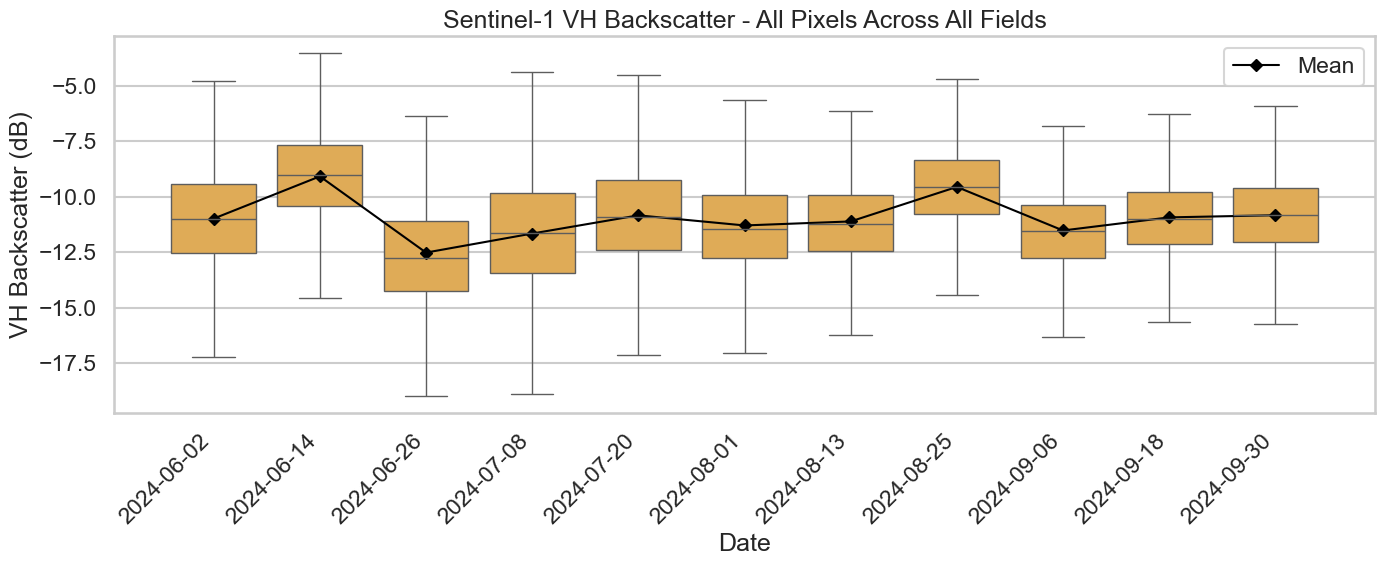

In [12]:
# ============================================================
# BOXPLOT: VH BACKSCATTER
# ============================================================

# Filter data
subset = df[df["Variable"] == "VH"].copy()

# Calculate means and ensure chronological order
mean_by_date = (
    subset.groupby("Date", as_index=False)
          .agg(
              Value=("Value", "mean"),
              DateSort=("DateSort", "min"),
          )
          .sort_values("DateSort")
)
order = mean_by_date["Date"].tolist()
mean_values = mean_by_date["Value"].tolist()

# Create plot
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=subset, x="Date", y="Value", order=order, showfliers=False, color="#f5b041", ax=ax)
ax.plot(range(len(order)), mean_values, marker="D", markersize=6, linewidth=1.5, color="black", label="Mean")

ax.set_title("Sentinel-1 VH Backscatter - All Pixels Across All Fields")
ax.set_xlabel("Date")
ax.set_ylabel("VH Backscatter (dB)")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.legend(loc="best")
fig.tight_layout()

# Save
for image_format in IMAGE_FORMATS:
    output_path = OUTPUT_DIR / f"vh_boxplot.{image_format}"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved VH boxplot to {output_path}")

plt.show()

Saved VV boxplot to data\boxplots\vv_boxplot.png
Saved VV boxplot to data\boxplots\vv_boxplot.jpg


Saved VV boxplot to data\boxplots\vv_boxplot.png
Saved VV boxplot to data\boxplots\vv_boxplot.jpg


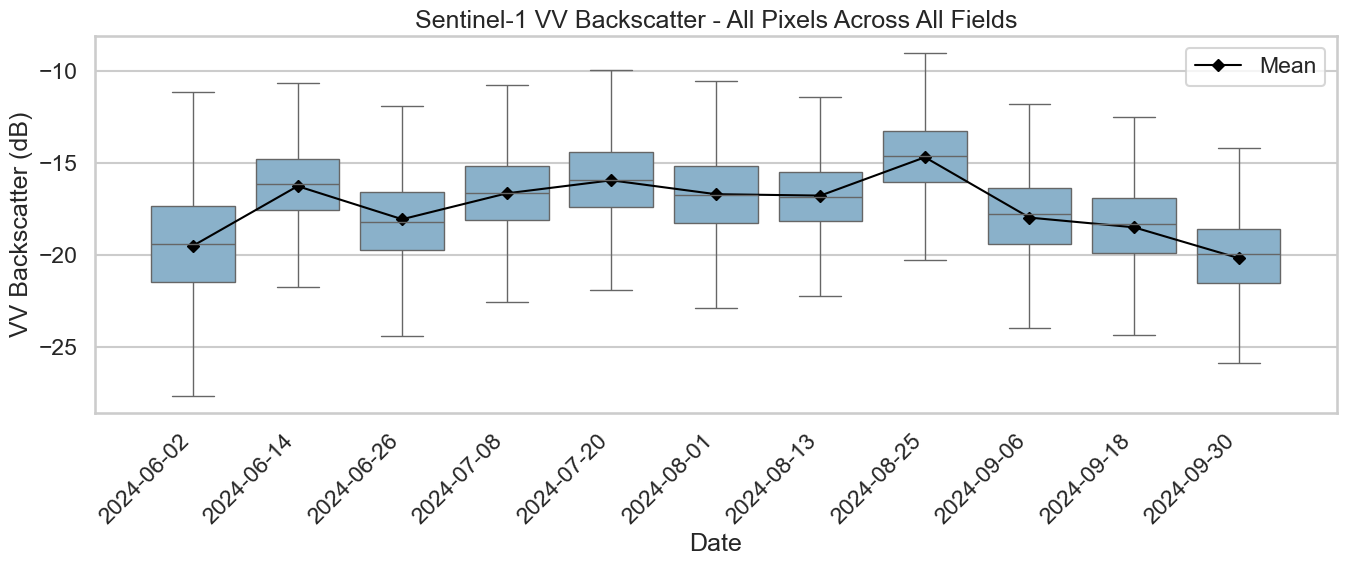

In [13]:
# ============================================================
# BOXPLOT: VV BACKSCATTER
# ============================================================

sns.set_theme(style="whitegrid", context="talk")

# Filter data
subset = df[df["Variable"] == "VV"].copy()

# Calculate means and ensure chronological order
mean_by_date = (
    subset.groupby("Date", as_index=False)
          .agg(
              Value=("Value", "mean"),
              DateSort=("DateSort", "min"),
          )
          .sort_values("DateSort")
)
order = mean_by_date["Date"].tolist()
mean_values = mean_by_date["Value"].tolist()

# Create plot
fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=subset, x="Date", y="Value", order=order, showfliers=False, color="#7fb3d5", ax=ax)
ax.plot(range(len(order)), mean_values, marker="D", markersize=6, linewidth=1.5, color="black", label="Mean")

ax.set_title("Sentinel-1 VV Backscatter - All Pixels Across All Fields")
ax.set_xlabel("Date")
ax.set_ylabel("VV Backscatter (dB)")
ax.set_xticks(range(len(order)))
ax.set_xticklabels(order, rotation=45, ha="right")
ax.legend(loc="best")
fig.tight_layout()

# Save
for image_format in IMAGE_FORMATS:
    output_path = OUTPUT_DIR / f"vv_boxplot.{image_format}"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    print(f"Saved VV boxplot to {output_path}")

plt.show()

In [14]:
# ============================================================
# LOAD DATA AND CREATE SUMMARIES
# ============================================================

# Load and prepare data
print(f"Scanning field rasters under: {DATA_ROOT}")
df = build_pixel_table(DATA_ROOT)

if df.empty:
    raise RuntimeError(f"No raster pixels were found under {DATA_ROOT}")

df = df.sort_values(["Variable", "DateSort"]).reset_index(drop=True)

# Display data info
print("\nData sample:")
print(df.head())
print("\nVariable counts:")
print(df["Variable"].value_counts())
print("\nSample by date:")
print(df.groupby(["Variable", "Date"]).size().head())

# Create summary statistics
summary = (
    df.groupby(["Variable", "Date"], as_index=False)
      .agg(
          pixel_count=("Value", "size"),
          mean_value=("Value", "mean"),
          median_value=("Value", "median"),
      )
)

# Save to CSV
df.to_csv(OUTPUT_DIR / "all_pixels_timeseries.csv", index=False)
summary.to_csv(OUTPUT_DIR / "pixel_summary_by_date.csv", index=False)

print(f"\nSaved pixel table to {OUTPUT_DIR / 'all_pixels_timeseries.csv'}")
print(f"Saved summary table to {OUTPUT_DIR / 'pixel_summary_by_date.csv'}")

Scanning field rasters under: data\fields\data

Data sample:
                      Date   DateSort   Variable     Value FieldId  \
0  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.206001   22583   
1  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.215767   22583   
2  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.240988   22583   
3  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.244927   22583   
4  2024-06-02 - 2024-06-14 2024-06-02  Coherence  0.189314   22583   

                                              Source  
0  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
1  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
2  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
3  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  
4  coherence_Coh_S1A_IW_SLC__1SDV_20240602_S1A_IW...  

Variable counts:
Variable
VH           3603890
VV           3603890
Coherence    3276652
Name: count, dtype: int64

Sample by date:
Variable   Date                   
Coherence  2024-06-0

In [15]:
# ============================================================
# HELPER FUNCTIONS
# ============================================================

def extract_date_tokens(filename):
    """Extract date tokens from raster filename."""
    tokens = re.findall(r"\d{8}T\d{6}|\d{8}", filename)
    if not tokens:
        raise ValueError(f"Could not parse a date from: {filename}")
    return tokens


def token_to_date_string(token):
    """Convert date token to YYYY-MM-DD."""
    fmt = "%Y%m%dT%H%M%S" if "T" in token else "%Y%m%d"
    return pd.to_datetime(token, format=fmt).strftime("%Y-%m-%d")


def parse_date_fields(filename, raster_type):
    """Create display label and sort key for date axis."""
    tokens = extract_date_tokens(filename)
    start_date = token_to_date_string(tokens[0])
    start_sort = pd.to_datetime(start_date)

    if raster_type == "coherence" and len(tokens) >= 2:
        end_date = token_to_date_string(tokens[1])
        date_label = f"{start_date} - {end_date}"
    else:
        date_label = start_date

    return date_label, start_sort


def infer_backscatter_labels(src):
    """Infer VV/VH labels from raster band descriptions, with a safe fallback."""
    descriptions = [(desc or "").upper() for desc in src.descriptions]
    if any("VV" in desc or "VH" in desc for desc in descriptions):
        labels = []
        for index, desc in enumerate(descriptions, start=1):
            if "VV" in desc:
                labels.append("VV")
            elif "VH" in desc:
                labels.append("VH")
            else:
                labels.append(f"Band {index}")
        return labels
    if src.count >= 2:
        return ["VV", "VH"] + [f"Band {i}" for i in range(3, src.count + 1)]
    if src.count == 1:
        return ["VV"]
    return [f"Band {i}" for i in range(1, src.count + 1)]


def iter_field_rasters(root):
    """Yield every extracted raster stored under the per-field dataset folders."""
    for field_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        for variable, subfolder in [("backscatter", "backscatter"), ("coherence", "coherence")]:
            folder = field_dir / subfolder
            if not folder.exists():
                continue
            for raster_path in sorted(folder.glob("*.tif")):
                yield field_dir.name, variable, raster_path


def build_pixel_table(root):
    """Build one long table with every valid pixel value across all fields and dates."""
    tables = []

    for field_id, raster_type, raster_path in iter_field_rasters(root):
        date_label, date_sort = parse_date_fields(raster_path.name, raster_type)
        with rasterio.open(raster_path) as src:
            data = src.read(masked=True)

            if raster_type == "backscatter":
                band_labels = infer_backscatter_labels(src)
            else:
                band_labels = ["Coherence"] * src.count

            for band_index in range(src.count):
                values = data[band_index].compressed()
                values = values[np.isfinite(values)]

                if raster_type == "coherence":
                    values = values[(values >= 0) & (values <= 1)]

                if values.size == 0:
                    continue

                variable = band_labels[band_index] if band_index < len(band_labels) else f"Band {band_index + 1}"
                frame = pd.DataFrame({
                    "Date": date_label,
                    "DateSort": date_sort,
                    "Variable": variable,
                    "Value": values.astype(float),
                    "FieldId": field_id,
                    "Source": raster_path.name,
                })
                tables.append(frame)

    if not tables:
        return pd.DataFrame(columns=["Date", "DateSort", "Variable", "Value", "FieldId", "Source"])
    return pd.concat(tables, ignore_index=True)


print("Helper functions defined.")

Helper functions defined.
